## 12 New-Location Visit Regularities (Flag 12)

### Dataset Overview
A constructed WorldTrace case with 240 trajectories. Route geometries come from observed NYC WorldTrace records and retain map-matched coordinates and OSM way identifiers. User, visit sequence, time, mode, vehicle, and weather context are arranged to realize the stated analysis goal.

The notebook exposes a primary table and a supporting table (`trajectory_points.csv`).

Goal: Analyze location-visiting patterns and driving behavior across first and repeated visits.

Role: Urban mobility analyst


Category: Exploration bursts, familiarity, speed, and directness

### Your Objective
Use the provided tables and visual results to answer the questions below and summarize the observed trajectory patterns.


## Import Necessary Libraries

This cell loads the data-analysis and visualization libraries used by the questions below.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, SVG, display

## Load Dataset

The primary table is loaded into `df`; the supporting timestamped trajectory-point table is loaded into `user_df`.

In [ ]:
dataset_path = 'trajectories.csv'
df = pd.read_csv(dataset_path)
df['departure_time'] = pd.to_datetime(df['departure_time'])
df['arrival_time'] = pd.to_datetime(df['arrival_time'])

In [ ]:
user_dataset_path = 'trajectory_points.csv'
user_df = pd.read_csv(user_dataset_path)

### **Question 1**: What portion of the user’s trajectory history consists of new-area visits, and where do those visits occur in the sequence?

#### Analysis action

Locate all new-location visits along the ordered trip history and compare them with familiar returns.

new visits 12 share 0.05
[1, 2, 46, 47, 48, 126, 127, 128, 206, 207, 208, 209]


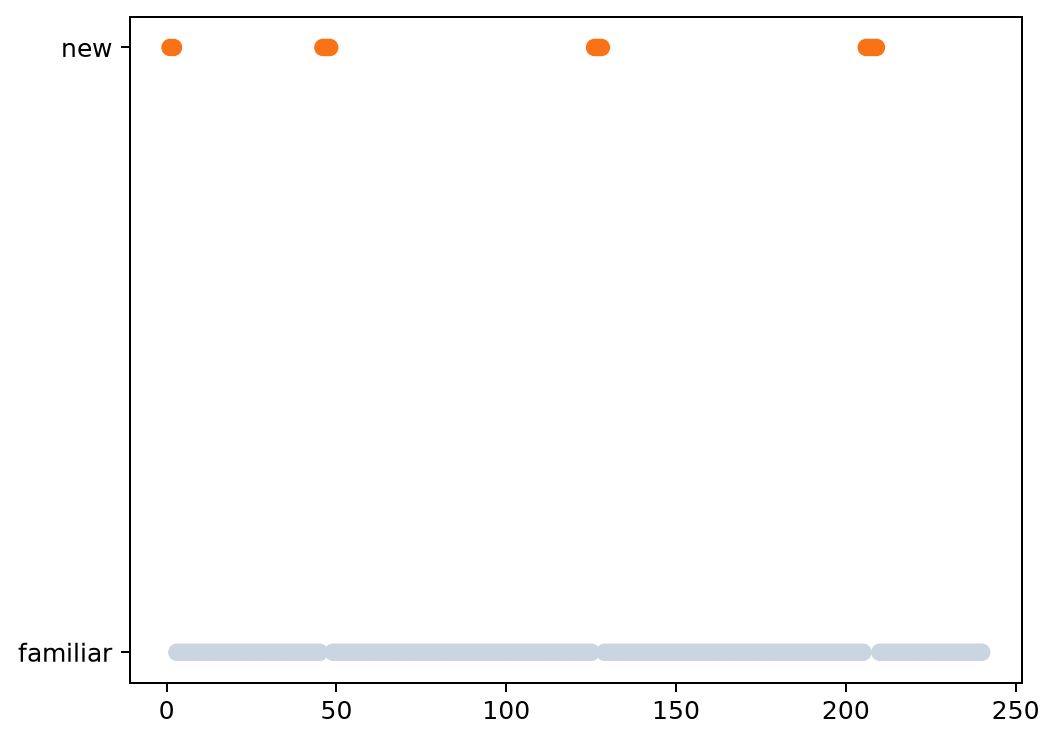

In [1]:
new=df[df.is_new_location_visit]; print('new visits',len(new),'share',len(new)/len(df)); print(new.trip_index.tolist()); plt.scatter(df.trip_index,df.is_new_location_visit.astype(int),c=np.where(df.is_new_location_visit,'#f97316','#cbd5e1')); plt.yticks([0,1],['familiar','new']); plt.show()
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/insight_1.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Medium (4 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "worldtrace_ex12_insight_1",
  "insight": "Although new-area visits account for only a small portion of the trajectory history, they are not evenly distributed over time.",
  "plot": {
    "plot_type": "map_and_statistical_summary",
    "files": [
      "visualizations/trajectory_map.png",
      "visualizations/insight_1.png"
    ],
    "title": "New-Location Visit Regularities: Insight 1",
    "description": "The geographic panel uses map-matched WorldTrace route geometry; the question-specific statistical plot summarizes the corresponding pattern."
  },
  "question": "What portion of the user’s trajectory history consists of new-area visits, and where do those visits occur in the sequence?",
  "actionable_insight": "Locate all new-location visits along the ordered trip history and compare them with familiar returns.",
  "code": "new=df[df.is_new_location_visit]; print('new visits',len(new),'share',len(new)/len(df)); print(new.trip_index.tolist()); plt.scatter(df.trip_index,df.is_new_location_visit.astype(int),c=np.where(df.is_new_location_visit,'#f97316','#cbd5e1')); plt.yticks([0,1],['familiar','new']); plt.show()",
  "insight_type": "overall_pattern",
  "difficulty_level": 4,
  "difficulty_label": "medium",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "trajectory_timestamp",
    "trajectory_id",
    "gps_position",
    "matched_road_position"
  ]
}

### **Question 2**: Do new-area visits form short exploration sequences separated by longer periods dominated by familiar returns?

#### Analysis action

Inspect the trip indices and intervals separating successive new-location visits.

indices [1, 2, 46, 47, 48, 126, 127, 128, 206, 207, 208, 209]
gaps [1, 44, 1, 1, 78, 1, 1, 78, 1, 1, 1]


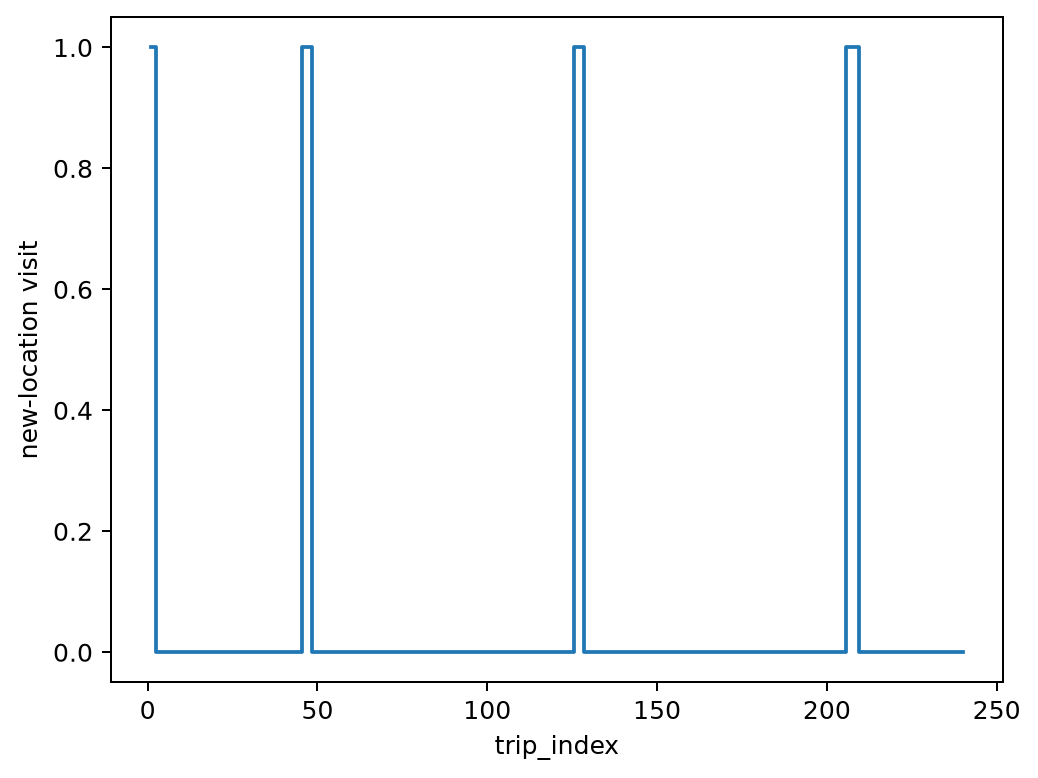

In [2]:
idx=df.loc[df.is_new_location_visit,'trip_index'].to_numpy(); print('indices',idx.tolist()); print('gaps',np.diff(idx).tolist()); pd.Series(np.isin(df.trip_index,idx).astype(int),index=df.trip_index).plot(drawstyle='steps-mid'); plt.ylabel('new-location visit'); plt.show()
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/insight_2.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Medium (4 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "worldtrace_ex12_insight_2",
  "insight": "Most new-area visits occur in several short sequences of consecutive explorations, separated by substantially longer periods dominated by returns to familiar areas.",
  "plot": {
    "plot_type": "map_and_statistical_summary",
    "files": [
      "visualizations/trajectory_map.png",
      "visualizations/insight_2.png"
    ],
    "title": "New-Location Visit Regularities: Insight 2",
    "description": "The geographic panel uses map-matched WorldTrace route geometry; the question-specific statistical plot summarizes the corresponding pattern."
  },
  "question": "Do new-area visits form short exploration sequences separated by longer periods dominated by familiar returns?",
  "actionable_insight": "Inspect the trip indices and intervals separating successive new-location visits.",
  "code": "idx=df.loc[df.is_new_location_visit,'trip_index'].to_numpy(); print('indices',idx.tolist()); print('gaps',np.diff(idx).tolist()); pd.Series(np.isin(df.trip_index,idx).astype(int),index=df.trip_index).plot(drawstyle='steps-mid'); plt.ylabel('new-location visit'); plt.show()",
  "insight_type": "overall_pattern",
  "difficulty_level": 4,
  "difficulty_label": "medium",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "trajectory_timestamp",
    "trajectory_id",
    "gps_position",
    "matched_road_position"
  ]
}

### **Question 3**: How does driving speed vary with the number of visits made to each location?

#### Analysis action

Compare location visit counts with mean driving speeds and quantify their association.

                  visits      speed
visited_location                   
place_1               50  42.765600
place_10               5  36.586000
place_11               3  35.203333
place_12               2  35.745000
place_2               45  41.199778
place_3               45  41.949778
place_4               30  40.156333
place_5               20  38.915500
place_6               15  38.206000
place_7               10  36.743000
place_8               10  37.342000
place_9                5  36.140000
correlation 0.9851167690700177


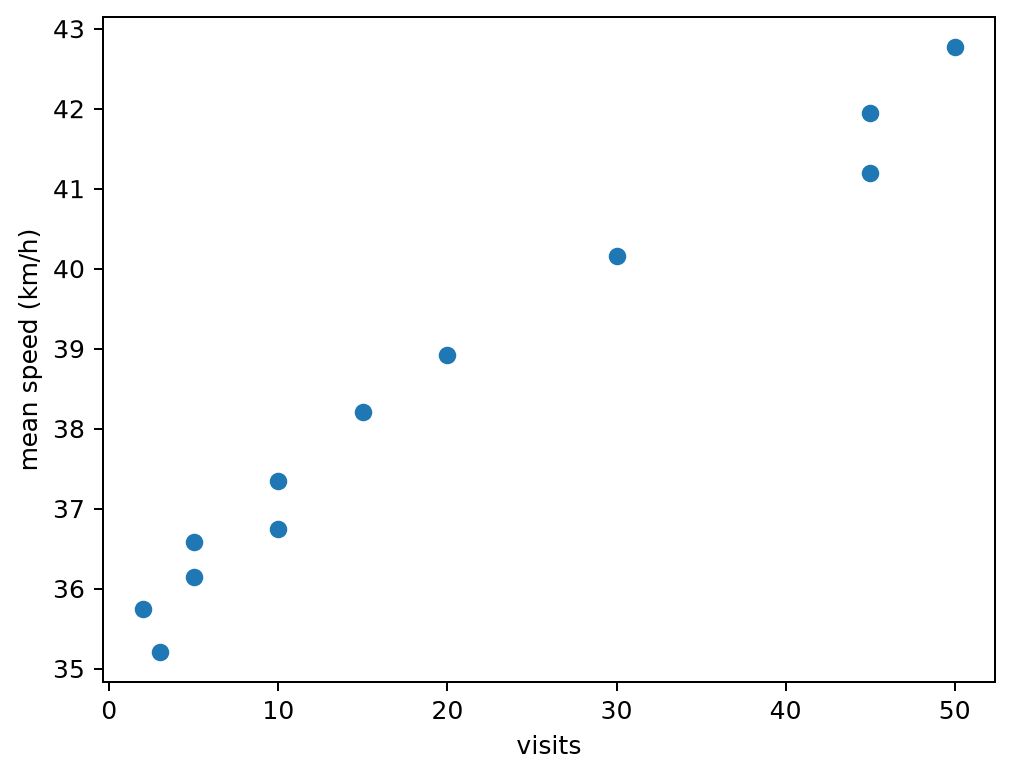

In [3]:
g=df.groupby('visited_location').agg(visits=('trajectory_id','size'),speed=('mean_speed_kmh','mean')); print(g); print('correlation',g.visits.corr(g.speed)); plt.scatter(g.visits,g.speed); plt.xlabel('visits'); plt.ylabel('mean speed (km/h)'); plt.show()
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/insight_3.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Medium (4 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "worldtrace_ex12_insight_3",
  "insight": "The more times the user visit the same location, the more likely the user drive faster to that location.",
  "plot": {
    "plot_type": "map_and_statistical_summary",
    "files": [
      "visualizations/trajectory_map.png",
      "visualizations/insight_3.png"
    ],
    "title": "New-Location Visit Regularities: Insight 3",
    "description": "The geographic panel uses map-matched WorldTrace route geometry; the question-specific statistical plot summarizes the corresponding pattern."
  },
  "question": "How does driving speed vary with the number of visits made to each location?",
  "actionable_insight": "Compare location visit counts with mean driving speeds and quantify their association.",
  "code": "g=df.groupby('visited_location').agg(visits=('trajectory_id','size'),speed=('mean_speed_kmh','mean')); print(g); print('correlation',g.visits.corr(g.speed)); plt.scatter(g.visits,g.speed); plt.xlabel('visits'); plt.ylabel('mean speed (km/h)'); plt.show()",
  "insight_type": "factor_relationship",
  "difficulty_level": 4,
  "difficulty_label": "medium",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "gps_position",
    "trajectory_timestamp",
    "trajectory_id",
    "matched_road_position"
  ]
}

### **Question 4**: How does route directness vary with the number of visits made to each location?

#### Analysis action

Compare location visit counts with route-distance-to-straight-line ratios; smaller ratios indicate greater directness.

                  visits  ratio
visited_location               
place_1               50  1.067
place_10               5  1.339
place_11               3  1.379
place_12               2  1.368
place_2               45  1.082
place_3               45  1.249
place_4               30  1.214
place_5               20  1.321
place_6               15  1.310
place_7               10  1.340
place_8               10  1.351
place_9                5  1.325
correlation -0.9095493050590863


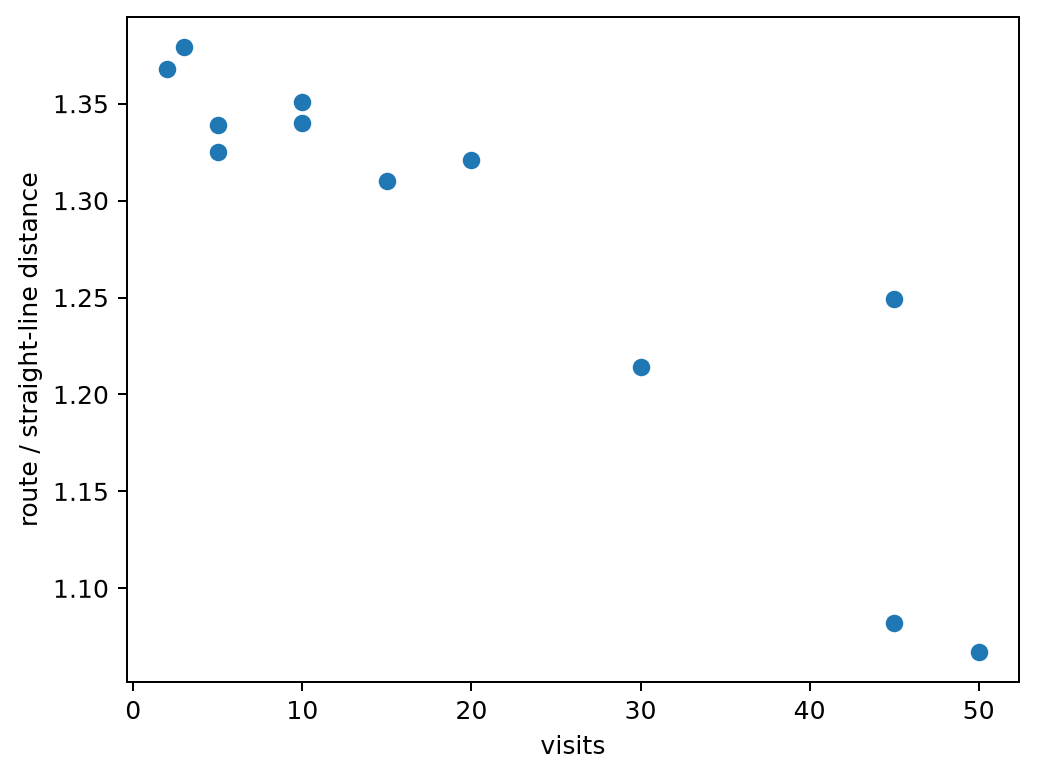

In [4]:
g=df.groupby('visited_location').agg(visits=('trajectory_id','size'),ratio=('route_directness_ratio','mean')); print(g); print('correlation',g.visits.corr(g.ratio)); plt.scatter(g.visits,g.ratio); plt.xlabel('visits'); plt.ylabel('route / straight-line distance'); plt.show()
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/insight_4.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Low (3 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "worldtrace_ex12_insight_4",
  "insight": "The more times the user visit the same location, the more likely the user drive with smaller route directness rate to that location.",
  "plot": {
    "plot_type": "map_and_statistical_summary",
    "files": [
      "visualizations/trajectory_map.png",
      "visualizations/insight_4.png"
    ],
    "title": "New-Location Visit Regularities: Insight 4",
    "description": "The geographic panel uses map-matched WorldTrace route geometry; the question-specific statistical plot summarizes the corresponding pattern."
  },
  "question": "How does route directness vary with the number of visits made to each location?",
  "actionable_insight": "Compare location visit counts with route-distance-to-straight-line ratios; smaller ratios indicate greater directness.",
  "code": "g=df.groupby('visited_location').agg(visits=('trajectory_id','size'),ratio=('route_directness_ratio','mean')); print(g); print('correlation',g.visits.corr(g.ratio)); plt.scatter(g.visits,g.ratio); plt.xlabel('visits'); plt.ylabel('route / straight-line distance'); plt.show()",
  "insight_type": "factor_relationship",
  "difficulty_level": 3,
  "difficulty_label": "low",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "gps_position",
    "trajectory_id",
    "matched_road_position"
  ]
}

### Summary of Findings (Flag 12)

Although new-area visits account for only a small portion of the trajectory history, they are not evenly distributed over time. Most new-area visits occur in several short sequences of consecutive explorations, separated by substantially longer periods dominated by returns to familiar areas. The more times the user visit the same location, the more likely the user drive faster to that location. The more times the user visit the same location, the more likely the user drive with smaller route directness rate to that location.